<a href="https://colab.research.google.com/github/iqbaal24/ML2026/blob/main/JS05_Klasterisasi_Hierarki_244107020105_MOHAMMAD_IQBAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1: HDBSCAN (Hierarchical Density-Based Spatial Clustering of Applications with Noise)

HDBSCAN, yaitu metode clustering berbasis kepadatan (densitas) yang lebih tahan banting dibanding DBSCAN. HDBSCAN tidak terlalu bergantung pada parameter `eps`, dan bisa menyesuaikan diri dengan data yang kepadatannya berbeda-beda. Kita juga akan mencoba pengaruh `min_cluster_size`, `min_samples`, dan `cut_distance`.

## Persiapan Lingkungan

In [1]:
# Instalasi pustaka hdbscan (tidak tersedia default di sklearn)
!pip install hdbscan

# Import modul
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import hdbscan

## Langkah 2: Definisi Fungsi Visualisasi

In [2]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

## Langkah 3: Membuat Dataset Sintetis

Dataset terdiri dari 3 cluster Gaussian dengan sebaran (kepadatan) yang berbeda.

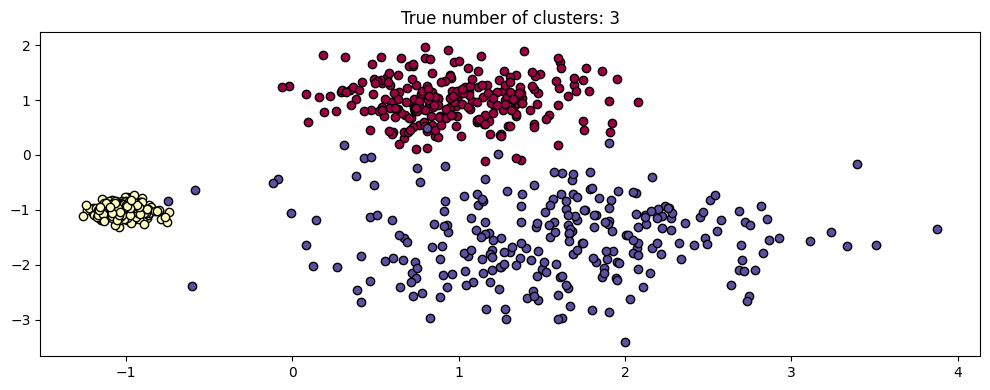

In [3]:
centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)

## Langkah 4: Uji *Scale Invariance* pada DBSCAN

Kita jalankan DBSCAN dengan `eps=0.3` pada data yang diubah skalanya (1, 0.5, dan 3 kali).

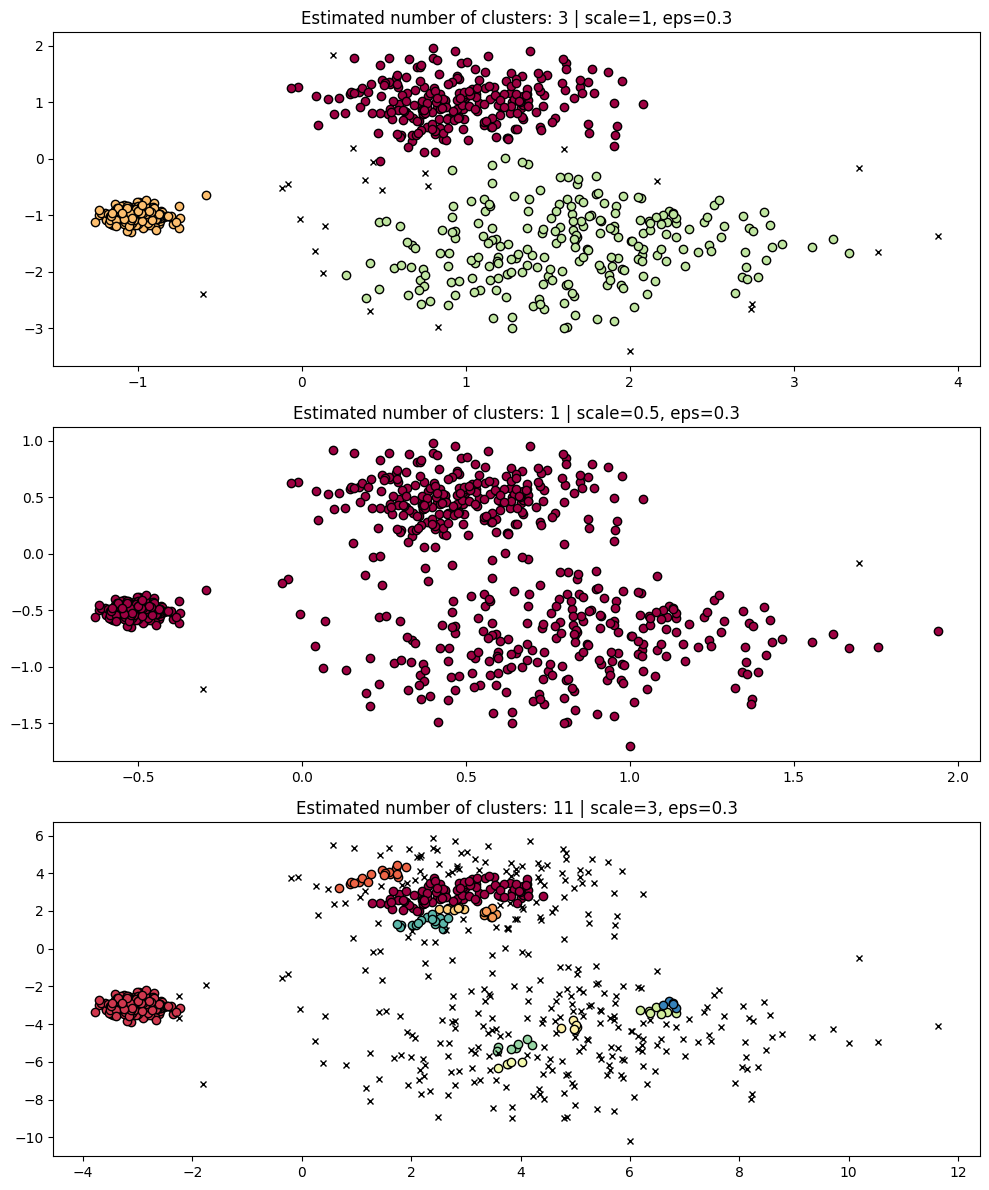

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])

**Analisis:** Dengan `eps` yang sama (0.3), hasil DBSCAN berubah-ubah mengikuti skala data. Saat skala diperkecil (0.5), jarak antar titik jadi kecil sehingga cluster-cluster bisa tergabung. Saat skala diperbesar (3), jarak antar titik jadi besar sehingga banyak titik dianggap noise atau cluster pecah. Artinya DBSCAN tidak *scale invariant*, jadi kita harus menyesuaikan `eps` setiap kali skala data berubah.

Perbaiki dengan mengubah `eps` sesuai skala (data dikali 3, maka `eps` juga dikali 3, yaitu 0.9):

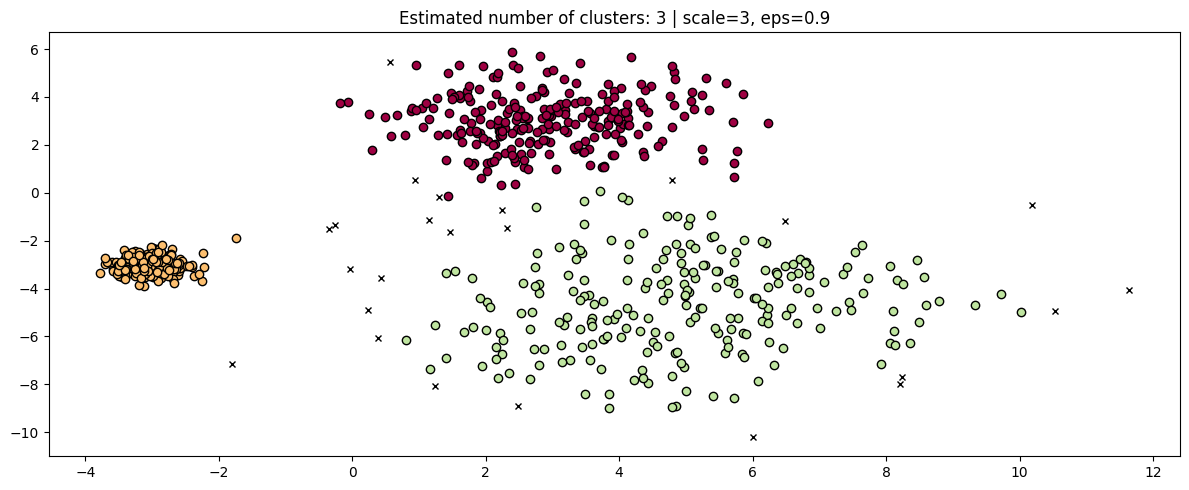

In [5]:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)

**Analisis:** Setelah `eps` disesuaikan menjadi 0.9, hasilnya kembali mirip dengan data berskala 1. Ini membuktikan bahwa masalah sebelumnya memang karena `eps` tidak ikut menyesuaikan skala.

## Langkah 5: Bandingkan dengan HDBSCAN (lebih robust)

Sekarang HDBSCAN dijalankan pada tiga skala yang sama, tanpa mengubah parameter apa pun.

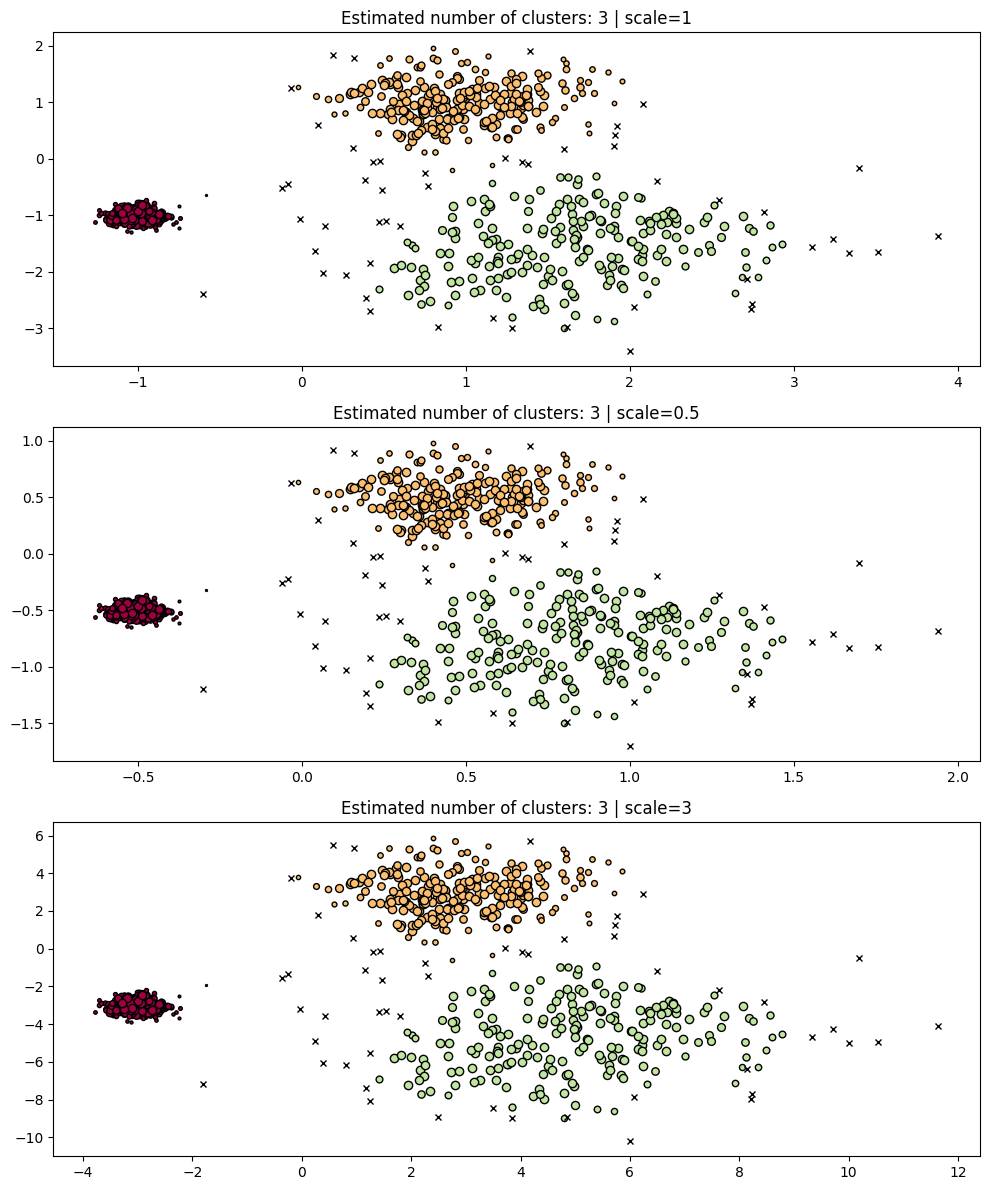

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

**Analisis:** HDBSCAN memberikan hasil yang konsisten di ketiga skala, yaitu sekitar 3 cluster, tanpa perlu mengatur `eps`. Ukuran titik pada plot menunjukkan `probabilities_`, yaitu seberapa yakin sebuah titik masuk ke clusternya (titik besar berarti lebih yakin). Jadi HDBSCAN bersifat *scale invariant*.

## Langkah 6: Multi-Scale Clustering

Buat dataset baru dengan kepadatan cluster yang berbeda-beda: dua cluster kecil dan padat, dua cluster besar dan renggang.

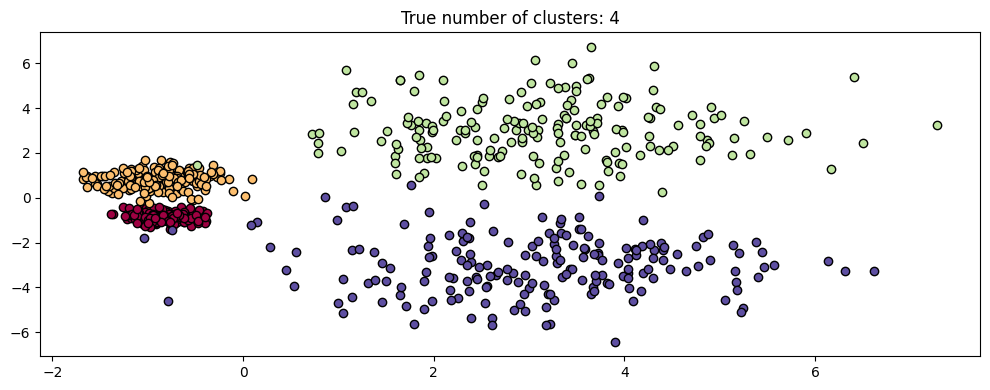

In [7]:
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)

Bandingkan DBSCAN dengan nilai `eps` berbeda:

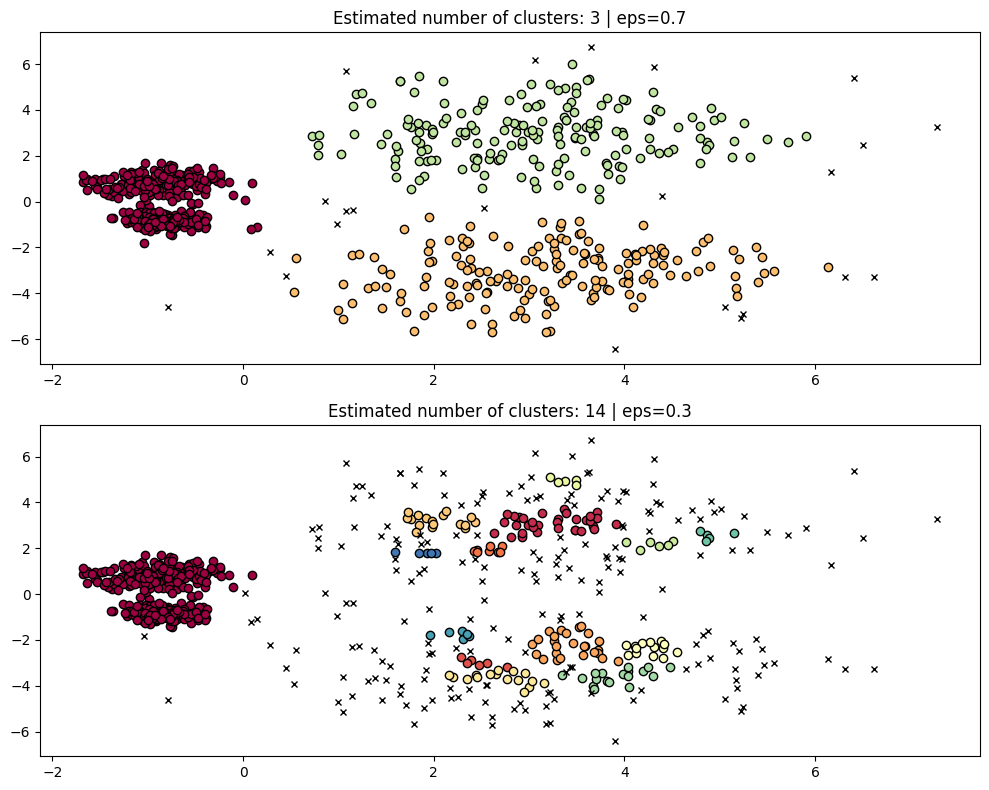

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])

**Analisis:** Dengan `eps=0.7`, dua cluster padat di kiri cenderung tergabung jadi satu karena jaraknya masih dalam jangkauan `eps`. Dengan `eps=0.3`, dua cluster padat terpisah dengan baik, tetapi cluster yang renggang di kanan banyak titiknya menjadi noise. Satu nilai `eps` tidak bisa cocok untuk semua cluster yang kepadatannya berbeda.

Sekarang jalankan HDBSCAN:

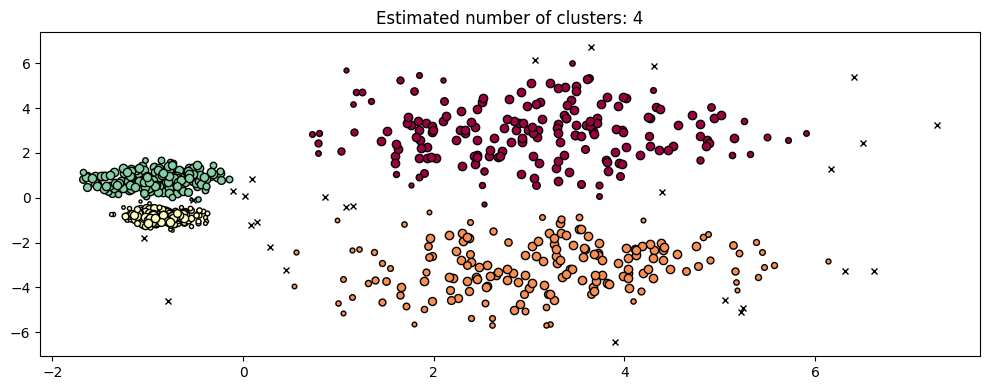

In [9]:
hdb = hdbscan.HDBSCAN().fit(X)
plot(X, hdb.labels_, hdb.probabilities_)

**Analisis:** HDBSCAN dapat menemukan keempat cluster sekaligus, baik yang padat maupun yang renggang, tanpa perlu menyetel `eps`. Ini karena HDBSCAN membangun hierarki cluster dari banyak tingkat kepadatan, lalu memilih cluster yang paling stabil.

## Langkah 7: Pengaruh `min_cluster_size`

`min_cluster_size` adalah jumlah titik minimum agar sekumpulan titik dianggap sebuah cluster. Kita coba beberapa nilai pada dataset multi-scale.

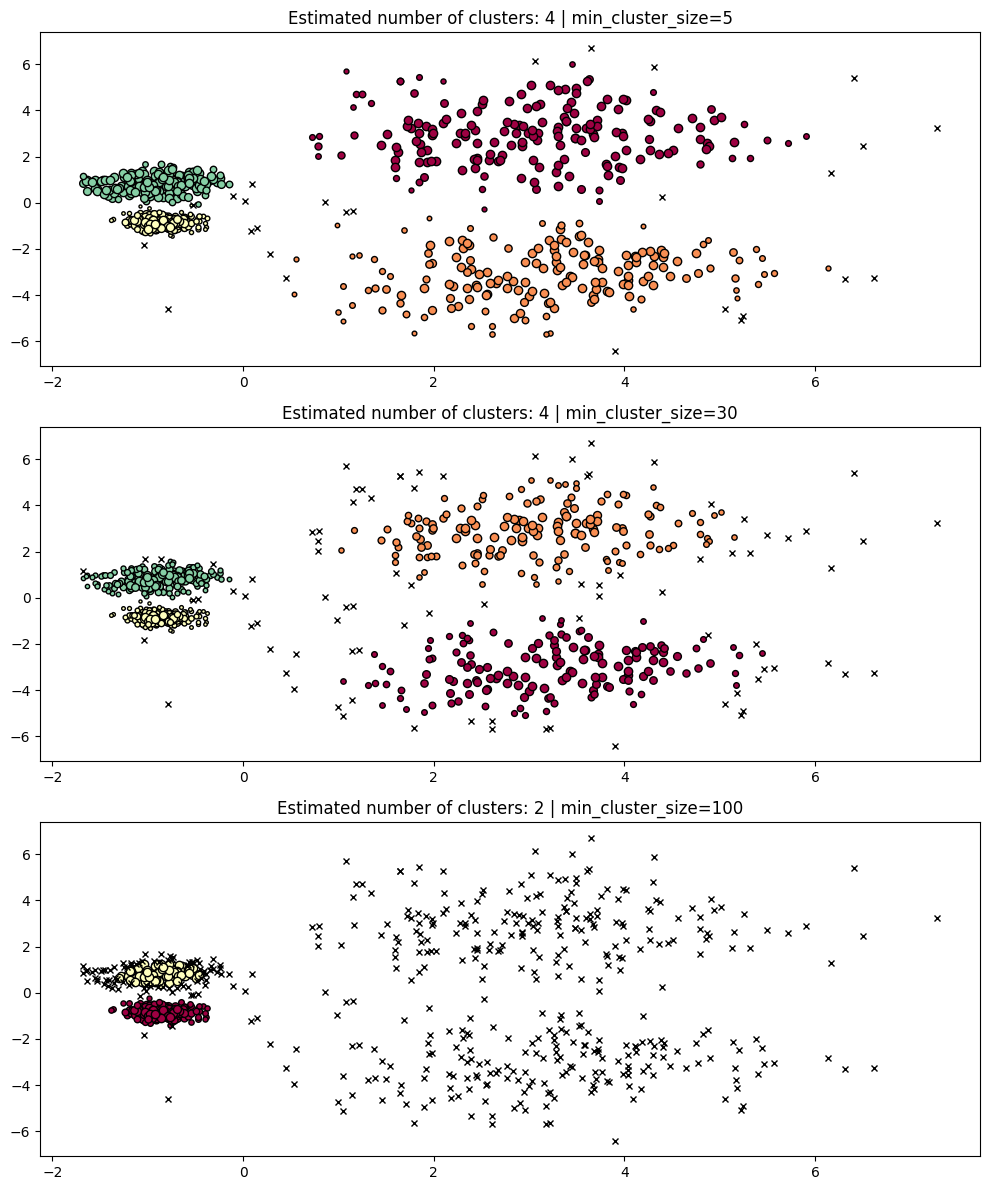

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for idx, mcs in enumerate([5, 30, 100]):
    hdb = hdbscan.HDBSCAN(min_cluster_size=mcs).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, parameters={"min_cluster_size": mcs}, ax=axes[idx])

**Analisis:** Nilai `min_cluster_size` kecil (misalnya 5) membuat HDBSCAN lebih sensitif sehingga bisa muncul cluster-cluster kecil tambahan. Nilai sedang (30) biasanya paling pas untuk data ini. Nilai besar (100) membuat cluster kecil tidak diakui, sehingga sebagian titik menjadi noise atau cluster tergabung. Jadi parameter ini mengatur seberapa kecil sebuah cluster boleh dianggap berarti.

## Langkah 8: Pengaruh `min_samples`

`min_samples` mengatur seberapa konservatif HDBSCAN dalam menentukan noise. Semakin besar nilainya, semakin banyak titik yang dianggap noise.

min_samples=1: jumlah noise = 9
min_samples=10: jumlah noise = 41
min_samples=40: jumlah noise = 128


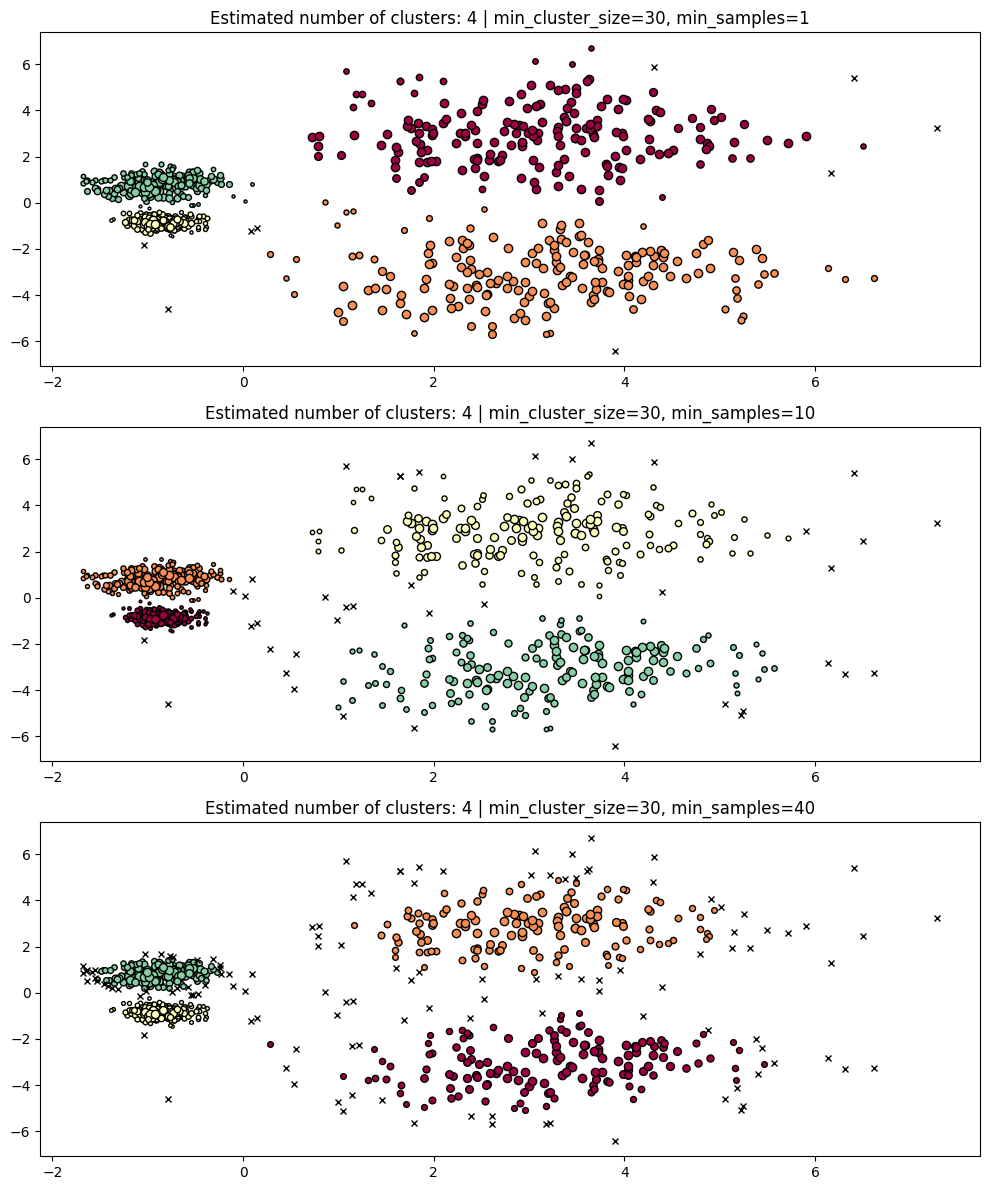

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for idx, ms in enumerate([1, 10, 40]):
    hdb = hdbscan.HDBSCAN(min_cluster_size=30, min_samples=ms).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, parameters={"min_cluster_size": 30, "min_samples": ms}, ax=axes[idx])
    print(f"min_samples={ms}: jumlah noise = {(hdb.labels_ == -1).sum()}")

**Analisis:** Saat `min_samples` kecil (1), hampir semua titik masuk ke suatu cluster dan noise sangat sedikit. Saat `min_samples` dinaikkan, area padat inti cluster dipertahankan sedangkan titik di pinggir cluster lebih banyak dianggap noise. Jadi `min_samples` berfungsi seperti pengatur "ketat atau longgarnya" definisi noise.

## Langkah 9: Pengaruh `cut_distance`

Secara bawaan HDBSCAN memilih cluster paling stabil dari pohon hierarki. Kita juga bisa memotong pohon hierarki pada jarak tertentu (`cut_distance`), mirip cara kerja DBSCAN dengan `eps`. Hasilnya diambil dari `single_linkage_tree_`.

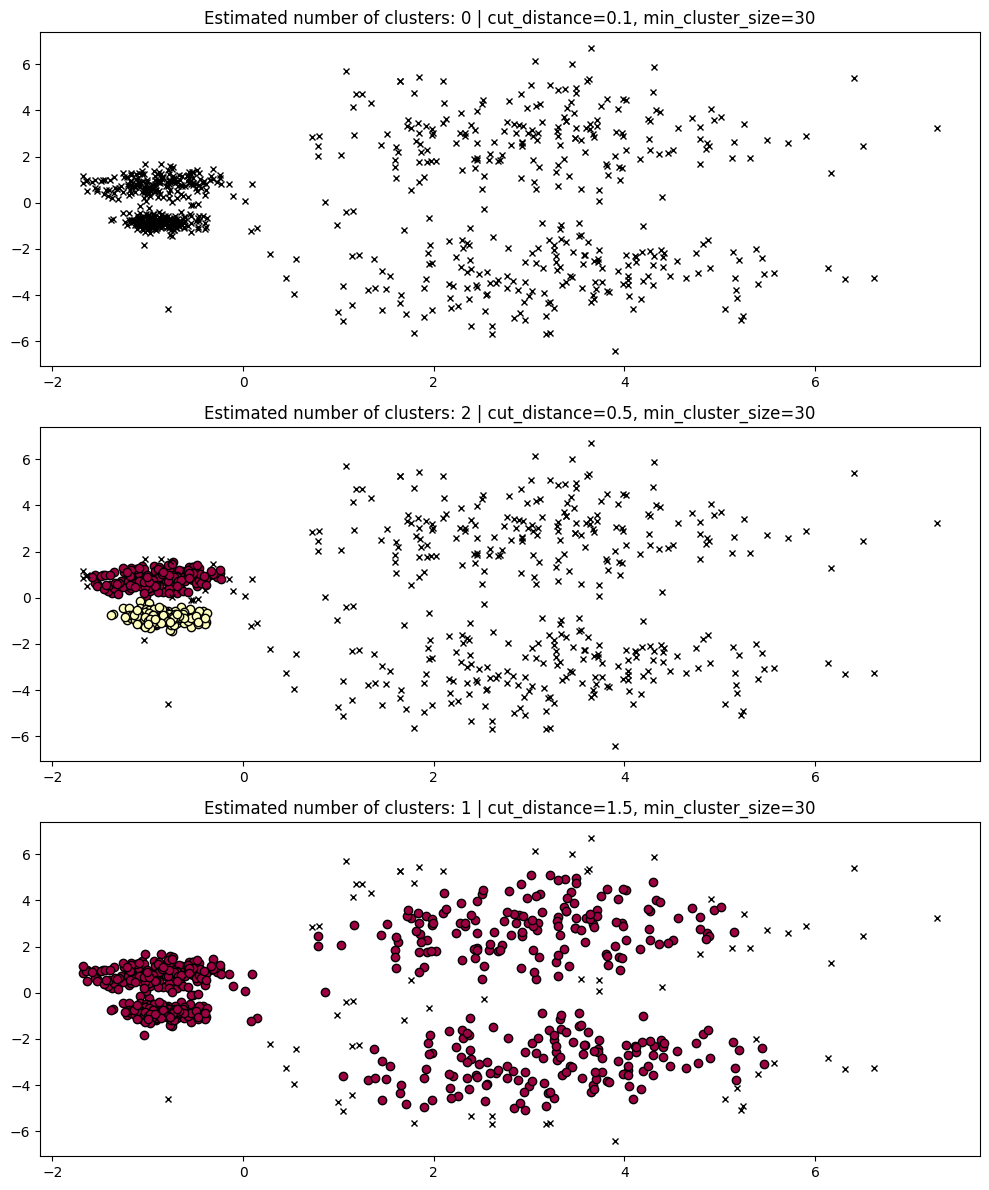

In [12]:
hdb = hdbscan.HDBSCAN(min_cluster_size=30).fit(X)

fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for idx, cut in enumerate([0.1, 0.5, 1.5]):
    labels_cut = hdb.single_linkage_tree_.get_clusters(cut_distance=cut, min_cluster_size=30)
    plot(X, labels_cut, parameters={"cut_distance": cut, "min_cluster_size": 30}, ax=axes[idx])

**Analisis:** Jika `cut_distance` kecil (0.1), pohon dipotong terlalu rendah sehingga hanya inti-inti yang sangat padat yang jadi cluster dan banyak titik menjadi noise. Jika `cut_distance` dinaikkan, cluster-cluster mulai terbentuk lebih lengkap. Jika terlalu besar (1.5), cluster yang berdekatan mulai bergabung. Pemotongan ini memakai satu ambang jarak untuk semua, jadi hasilnya mirip DBSCAN dan kurang mampu menangani kepadatan yang berbeda dibanding pilihan otomatis HDBSCAN.

## Kesimpulan

DBSCAN sangat bergantung pada `eps`, sehingga hasilnya berubah jika skala data berubah dan sulit menangani cluster dengan kepadatan berbeda. HDBSCAN mengatasi hal ini dengan membangun hierarki cluster dari banyak tingkat kepadatan, sehingga hasilnya konsisten pada berbagai skala dan mampu menemukan cluster padat maupun renggang sekaligus. Parameter utama HDBSCAN lebih mudah dipahami: `min_cluster_size` mengatur ukuran minimum cluster, `min_samples` mengatur seberapa ketat penentuan noise, dan `cut_distance` memungkinkan pemotongan hierarki secara manual bila diperlukan.